# Chapter 20: Weight decay and early stopping

Checks [chapter 20](../../book/20-weight-decay-and-early-stopping.md). The model is **linear in its weights**, with squared
error and a fixed kernel, which is the model `WeightDecay.lean` is about. Its features are a constant and the cosines and
sines of the integer frequencies 1 to 20 (fixed, not trained), each divided by its frequency so that low frequencies are the strong directions of the kernel. Training moves only the coefficients. Everything is NumPy
in float64, seeded. These are measurements, not proofs: the proofs are in `WeightDecay.lean`. Run every cell, top to
bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 20

## Claim 1: weight decay leaves the share `decay_strength / (kernel_strength + decay_strength)` (`weight_decay_leaves_a_share_of_the_residual`)

The chapter's example: one weight, one feature of size 2 (kernel strength 4), label 10, start weight 0,
`decay_strength = 1`, `learning_rate = 0.1`. Gradient descent on `0.5 (label - feature w)^2 + 0.5 decay_strength w^2` is run
for 200 steps, not solved by the formula.

**Predicted:** the weight rests at 4, the error left is 2, which is 0.2 of 10, and each step multiplies the distance to the
resting weight by `1 - learning_rate (strength + decay) = 0.5`, so `w -> 0.5 w + 2`. Without decay the weight goes to 5, the
error to 0, and the factor is `1 - 0.1 * 4 = 0.6`. **Against the claim:** a resting weight other than 4, or a share other
than 0.2. The no-decay run is the control: there the share left must be 0, so the share 0.2 comes from the penalty.

In [2]:
FEATURE = 2.0
LABEL = 10.0
LEARNING_RATE = 0.1


def descend_one_weight(decay_strength, step_count):
    """Gradient descent with decay on one weight, from 0. Returns the weight after every step."""
    weight = 0.0
    weights = [weight]
    for _ in range(step_count):
        error = LABEL - FEATURE * weight
        weight = weight + LEARNING_RATE * (FEATURE * error - decay_strength * weight)
        weights.append(weight)
    return np.array(weights)


with_decay = descend_one_weight(1.0, 200)
without_decay = descend_one_weight(0.0, 200)
share_with_decay = (LABEL - FEATURE * with_decay[-1]) / LABEL
share_without_decay = (LABEL - FEATURE * without_decay[-1]) / LABEL
# the measured factor per step: distance to the limit after one step over the distance before it
factor_with_decay = (with_decay[6] - with_decay[-1]) / (with_decay[5] - with_decay[-1])
factor_without_decay = (without_decay[6] - without_decay[-1]) / (without_decay[5] - without_decay[-1])
report("weight decay: the weight rests at 4", abs(with_decay[-1] - 4.0) < 1e-12, f"weight {with_decay[-1]:.12f}")
report("weight decay: the share of the error left is 0.2", abs(share_with_decay - 0.2) < 1e-12,
       f"share {share_with_decay:.12f}")
report("weight decay: the weights go 2, 3, 3.5, 3.75 (w -> 0.5 w + 2)",
       np.allclose(with_decay[1:5], [2.0, 3.0, 3.5, 3.75]) and abs(factor_with_decay - 0.5) < 1e-9,
       f"measured factor per step {factor_with_decay:.6f}")
report("control, no decay: the weight goes to 5 and no error is left",
       abs(without_decay[-1] - 5.0) < 1e-9 and abs(share_without_decay) < 1e-9 and abs(factor_without_decay - 0.6) < 1e-9,
       f"weight {without_decay[-1]:.9f}, share {share_without_decay:.1e}, factor {factor_without_decay:.6f}")

[PASS] weight decay: the weight rests at 4  (weight 4.000000000000)
[PASS] weight decay: the share of the error left is 0.2  (share 0.200000000000)
[PASS] weight decay: the weights go 2, 3, 3.5, 3.75 (w -> 0.5 w + 2)  (measured factor per step 0.500000)
[PASS] control, no decay: the weight goes to 5 and no error is left  (weight 5.000000000, share 1.8e-16, factor 0.600000)


True

## Claim 2: early stopping leaves no more than weight decay at the matching penalty (`early_stopping_leaves_at_most_what_weight_decay_leaves`)

One pattern of strength `s`, label 10, `learning_rate = 0.1`, `step_count = 10`. Plain gradient descent, no decay. The
feature is `sqrt(s)`, so the kernel strength is `s`.

**Predicted:** for `s = 5` the share left is `0.5^10`, about 0.00098, under the bound `1 / (1 + 10 * 0.5) = 1/6`. For
`s = 0.05` it is `0.995^10`, about 0.951, under the bound `1 / 1.05`, about 0.952. **Against the claim:** a measured share above
the bound at any step. The sweep checks every step from 0 to 300 for 40 rates in `[0, 1]`. The control breaks the hypothesis
`rate <= 1`: at rate 1.9 gradient descent still converges, but the bound must fail, and the size of the failure is reported.

In [3]:
def descend_one_pattern(kernel_strength, step_count):
    """Share of the error left after every step of plain gradient descent on one pattern."""
    feature = np.sqrt(kernel_strength)
    weight = 0.0
    shares = [1.0]
    for _ in range(step_count):
        error = LABEL - feature * weight
        weight = weight + LEARNING_RATE * feature * error
        shares.append((LABEL - feature * weight) / LABEL)
    return np.array(shares)


def bound_on_share(rate, steps):
    return 1.0 / (1.0 + steps * rate)


STEP_COUNT = 10
strong_shares = descend_one_pattern(5.0, STEP_COUNT)
weak_shares = descend_one_pattern(0.05, STEP_COUNT)
strong_bound = bound_on_share(0.5, STEP_COUNT)
weak_bound = bound_on_share(0.005, STEP_COUNT)
report("strong pattern: share left after 10 steps is 0.5^10, under the bound 1/6",
       abs(strong_shares[-1] - 0.5 ** 10) < 1e-12 and strong_shares[-1] <= strong_bound,
       f"share {strong_shares[-1]:.6f}, bound {strong_bound:.6f}")
report("weak pattern: share left is 0.995^10, under the bound 1/1.05",
       abs(weak_shares[-1] - 0.995 ** 10) < 1e-12 and weak_shares[-1] <= weak_bound,
       f"share {weak_shares[-1]:.6f}, bound {weak_bound:.6f}")

worst_margin = np.inf
for rate in np.linspace(0.0, 1.0, 40):
    steps = np.arange(0, 301)
    measured = descend_one_pattern(rate / LEARNING_RATE, 300)
    worst_margin = min(worst_margin, float((bound_on_share(rate, steps) - measured).min()))
report("the bound holds at every step, for 40 rates in [0, 1]", worst_margin >= -1e-12, f"smallest bound minus share {worst_margin:.2e}")

control_rate = 1.9
control_steps = np.arange(0, 4)
control_shares = np.abs(descend_one_pattern(control_rate / LEARNING_RATE, 3))
control_bound = bound_on_share(control_rate, control_steps)
failure = float((control_shares - control_bound).max())
report("control, rate 1.9 (above 1): the bound fails", failure > 0.1,
       f"size of the failure: error share {control_shares[3]:.3f} against bound {control_bound[3]:.3f} at step 3")

[PASS] strong pattern: share left after 10 steps is 0.5^10, under the bound 1/6  (share 0.000977, bound 0.166667)
[PASS] weak pattern: share left is 0.995^10, under the bound 1/1.05  (share 0.951110, bound 0.952381)
[PASS] the bound holds at every step, for 40 rates in [0, 1]  (smallest bound minus share 0.00e+00)
[PASS] control, rate 1.9 (above 1): the bound fails  (size of the failure: error share 0.729 against bound 0.149 at step 3)


True

## Claim 3: the matching penalty gives the same number (`matching_penalty_gives_the_same_share`)

With `decay_strength = 1 / (learning_rate * step_count)`, weight decay leaves `decay / (strength + decay)`. Here the ridge fit
is **solved on data**: 8 random data points, 12 weights, random labels, the weights `features^T (K + decay I)^{-1} labels` from
a linear solve. The share left is read off that solution, along each of the 8 eigenvectors of `K = features features^T`, as the
error left along it over the label along it. It is compared with `1 / (1 + step_count * learning_rate * strength)` for that
eigenvector's strength. The grid is up to 60 distinct whole values of `step_count` from 1 to 5000 and 5 learning rates; the output counts the comparisons.

**Predicted:** agreement to rounding, about `1e-12` (the linear solve loses a little for tiny strengths). **Against the claim:**
a difference above `1e-9`. The control uses a penalty that is *not* matched (the one for `2 * step_count` steps): the
difference must then be large, and its size is reported. The chapter's one-weight case is also checked, with its resting
weight written as the closed form `feature * label / (feature^2 + decay)`, which is a formula, not a solve.

In [4]:
def solve_ridge_share(kernel_strength, decay_strength):
    """One-weight case: share left at the closed-form resting weight (a formula, not a solve)."""
    feature = np.sqrt(kernel_strength)
    weight = feature * LABEL / (feature ** 2 + decay_strength)
    return (LABEL - feature * weight) / LABEL


def solve_ridge_shares_along_directions(features, labels, decay_strength):
    """Solve the ridge fit by a linear system, then the share of the label left along each kernel direction."""
    kernel = features @ features.T
    strengths, directions = np.linalg.eigh(kernel)
    fit_weights = features.T @ np.linalg.solve(kernel + decay_strength * np.eye(len(labels)), labels)
    error = labels - features @ fit_weights
    return strengths, (directions.T @ error) / (directions.T @ labels)


solve_generator = np.random.default_rng(SEED + 1)
solve_features = solve_generator.standard_normal((8, 12))
solve_labels = solve_generator.standard_normal(8)
largest_gap = 0.0
control_gap = 0.0
comparisons = 0
for learning_rate in (0.01, 0.05, 0.1, 0.5, 1.0):
    for step_count in np.unique(np.geomspace(1, 5000, 60).astype(int)):
        decay_strength = 1.0 / (learning_rate * step_count)
        direction_strengths, solved_shares = solve_ridge_shares_along_directions(solve_features, solve_labels, decay_strength)
        stopped_bound = 1.0 / (1.0 + step_count * (learning_rate * direction_strengths))
        largest_gap = max(largest_gap, float(np.abs(solved_shares - stopped_bound).max()))
        _, unmatched_shares = solve_ridge_shares_along_directions(solve_features, solve_labels, 1.0 / (learning_rate * 2 * step_count))
        control_gap = max(control_gap, float(np.abs(unmatched_shares - stopped_bound).max()))
        comparisons += len(direction_strengths)
report("solved ridge share along each direction equals the stopping bound", largest_gap < 1e-9,
       f"{comparisons} comparisons, largest difference {largest_gap:.1e}")
report("control, the penalty for twice the steps: the solved share differs from the bound", control_gap > 0.05,
       f"largest difference {control_gap:.3f}")

matched = solve_ridge_share(5.0, 1.0 / (0.1 * 10))
unmatched = solve_ridge_share(5.0, 1.0 / (0.1 * 20))
report("the chapter's case, closed form: decay 1 leaves 1/6", abs(matched - 1.0 / 6.0) < 1e-12, f"share {matched:.9f}")
report("control, closed form, the penalty for 20 steps leaves a different share", abs(unmatched - 1.0 / 6.0) > 0.05,
       f"share {unmatched:.4f}, miss {abs(unmatched - 1.0 / 6.0):.4f}")

[PASS] solved ridge share along each direction equals the stopping bound  (2080 comparisons, largest difference 2.1e-15)
[PASS] control, the penalty for twice the steps: the solved share differs from the bound  (largest difference 0.172)
[PASS] the chapter's case, closed form: decay 1 leaves 1/6  (share 0.166666667)
[PASS] control, closed form, the penalty for 20 steps leaves a different share  (share 0.0909, miss 0.0758)


True

## Claim 4: both habits put a floor under the weak patterns

The model has 30 data points and 41 weights (a constant and cosine and sine up to frequency 20, each divided by its frequency), so the kernel
`K = features features^T` is a 30 by 30 matrix with strengths spread over several powers of ten. The labels are random,
so they have a part along every eigenvector of `K`. Two fits are made from the start weights 0: gradient descent for
`step_count = 40` steps at `learning_rate = 1 / (largest strength)`, and the weight-decay fit with the matched
`decay_strength = 1 / (learning_rate * step_count)`, solved in closed form. For each eigenvector, the **share fitted** is
`1 - (error left along it) / (error before along it)`.

**Predicted:** the share fitted by weight decay is `strength / (strength + decay)`, by early stopping `1 - (1 - learning_rate *
strength)^step_count`, and early stopping fits at least as much as weight decay in every direction (the chapter's theorem, which
says it leaves no more). Both curves are small for a strength well under `decay` and near 1 well over it, but that follows from the formulas, so it is printed and not checked. **Against the
claim:** a measured share off its formula by more than `1e-9`, or early stopping fitting less than weight decay in a direction where the two differ by more than `1e-6`. Control: the same fit with `decay` set to 0
fits everything, with no floor.

In [5]:
def make_features(inputs, top_frequency=20):
    columns = [np.ones_like(inputs)]
    for frequency in range(1, top_frequency + 1):
        columns.append(np.cos(frequency * inputs) / frequency)
        columns.append(np.sin(frequency * inputs) / frequency)
    return np.stack(columns, axis=1)


generator = np.random.default_rng(SEED)
train_inputs = generator.uniform(0, 2 * np.pi, 30)
features = make_features(train_inputs)
kernel = features @ features.T
strengths, directions = np.linalg.eigh(kernel)
strengths, directions = strengths[::-1], directions[:, ::-1]
direction_learning_rate = 1.0 / strengths[0]
direction_steps = 40
direction_decay = 1.0 / (direction_learning_rate * direction_steps)
labels = generator.standard_normal(30)

weights = np.zeros(features.shape[1])
for _ in range(direction_steps):
    weights = weights + direction_learning_rate * features.T @ (labels - features @ weights)
stopped_error = labels - features @ weights

ridge_weights = features.T @ np.linalg.solve(kernel + direction_decay * np.eye(30), labels)
ridge_error = labels - features @ ridge_weights
nodecay_weights = features.T @ np.linalg.solve(kernel + 1e-12 * np.eye(30), labels)
nodecay_error = labels - features @ nodecay_weights

start_along = directions.T @ labels
fitted_stopped = 1.0 - (directions.T @ stopped_error) / start_along
fitted_ridge = 1.0 - (directions.T @ ridge_error) / start_along
fitted_nodecay = 1.0 - (directions.T @ nodecay_error) / start_along
formula_ridge = strengths / (strengths + direction_decay)
formula_stopped = 1.0 - (1.0 - direction_learning_rate * strengths) ** direction_steps

gap_ridge = float(np.abs(fitted_ridge - formula_ridge).max())
gap_stopped = float(np.abs(fitted_stopped - formula_stopped).max())
report("weight decay fits strength / (strength + decay) in every direction", gap_ridge < 1e-9, f"largest gap {gap_ridge:.1e}")
report("early stopping fits 1 - (1 - rate)^steps in every direction", gap_stopped < 1e-9, f"largest gap {gap_stopped:.1e}")
differ = np.abs(fitted_stopped - fitted_ridge) > 1e-6
extra = (fitted_stopped - fitted_ridge)[differ]
report("early stopping fits at least as much as weight decay, in the directions where the two differ by more than 1e-6",
       differ.sum() > 0 and extra.min() > 0, f"{int(differ.sum())} of 30 directions differ; smallest difference {extra.min():.2e}")
weak = strengths < 0.05 * direction_decay
strong = strengths > 20 * direction_decay
print(f"for information, not checked (it follows from the definitions of weak and strong): {int(weak.sum())} directions below 0.05 * decay "
      f"have at most {fitted_ridge[weak].max():.4f} fitted by decay and {fitted_stopped[weak].max():.4f} by stopping; "
      f"{int(strong.sum())} above 20 * decay have at least {fitted_ridge[strong].min():.4f} and {fitted_stopped[strong].min():.4f}")
report("control, no decay: even the weakest direction is fitted", fitted_nodecay.min() > 0.999,
       f"least fitted share {fitted_nodecay.min():.6f}; strengths from {strengths.min():.2e} to {strengths.max():.1f}")
print(f"decay_strength = {direction_decay:.3f}")

[PASS] weight decay fits strength / (strength + decay) in every direction  (largest gap 4.1e-14)
[PASS] early stopping fits 1 - (1 - rate)^steps in every direction  (largest gap 4.2e-14)
[PASS] early stopping fits at least as much as weight decay, in the directions where the two differ by more than 1e-6  (26 of 30 directions differ; smallest difference 3.55e-06)
for information, not checked (it follows from the definitions of weak and strong): 11 directions below 0.05 * decay have at most 0.0431 fitted by decay and 0.0440 by stopping; 2 above 20 * decay have at least 0.9596 and 1.0000
[PASS] control, no decay: even the weakest direction is fitted  (least fitted share 0.999859; strengths from 7.10e-09 to 31.6)
decay_strength = 0.791


## Figure: the floor under the weak directions

Written to `book/figures/20-weak-directions.png`. Each point is one direction of the kernel: its strength on the
horizontal axis (log) and the share of the label along it that the fit has taken, measured, on the vertical axis. Blue:
early stopping after 40 steps. Orange: weight decay at the matching penalty. The lines are the two formulas. Grey: no decay.

wrote book/figures/20-weak-directions.png


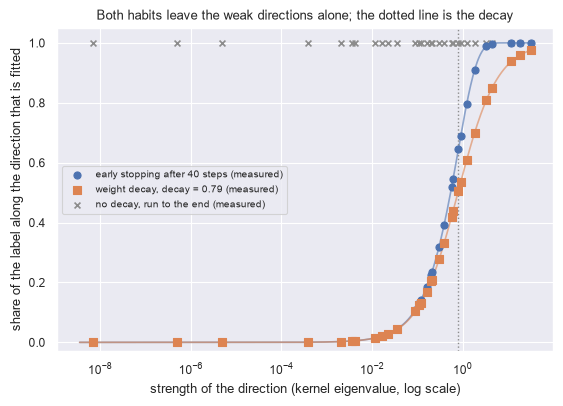

In [6]:
figure, axis = plt.subplots(figsize=(6.4, 4.2))
curve_strengths = np.geomspace(strengths.min() / 2, strengths[0], 400)
axis.plot(curve_strengths, 1.0 - (1.0 - direction_learning_rate * curve_strengths) ** direction_steps, color=NEAREST,
          linewidth=1.2, alpha=0.6)
axis.plot(curve_strengths, curve_strengths / (curve_strengths + direction_decay), color=VERTICAL, linewidth=1.2, alpha=0.6)
axis.scatter(strengths, fitted_stopped, color=NEAREST, s=26, zorder=3, label=f"early stopping after {direction_steps} steps (measured)")
axis.scatter(strengths, fitted_ridge, color=VERTICAL, s=26, marker="s", zorder=3,
             label=f"weight decay, decay = {direction_decay:.2g} (measured)")
axis.scatter(strengths, fitted_nodecay, color=BEFORE, s=18, marker="x", zorder=2, label="no decay, run to the end (measured)")
axis.axvline(direction_decay, color=BEFORE, linestyle=":", linewidth=1.0)
axis.set_xscale("log")
axis.set_ylim(-0.03, 1.05)
axis.set_xlabel("strength of the direction (kernel eigenvalue, log scale)")
axis.set_ylabel("share of the label along the direction that is fitted")
axis.set_title("Both habits leave the weak directions alone; the dotted line is the decay")
axis.legend(loc="center left", fontsize=7.5)
save_figure(figure, "20-weak-directions")

## Claim 5: stopping early helps on noisy labels

The same 41 features. The truth is `sin(x) + 0.5 cos(2x)`. There are 30 training points, 200 validation points and 2000
test points, all with fresh noise of standard deviation 0.5 (noise variance 0.25). Gradient descent from weights 0 at
`learning_rate = 1 / (largest strength)` for 3000 steps. The stopping step is the one with the lowest **validation**
error, chosen before the test set is looked at. The same run with noise 0 is the control.

**Predicted:** the train error falls at every step. With noise, the test error falls, reaches a minimum at a step well before
3000, and then rises, so the test error at the stopping step is lower than at the end by a clear margin. With no noise
there is nothing to stop for: the test error should keep falling to the end. **Against the claim:** with noise, a test error at the
stopping step not at least 20 percent below the test error at step 3000; or, in the control, a test error at the end more than 5
percent above its lowest value. Also reported: weight decay at the penalty matched to the stopping step, solved
directly, with the test error it reaches.

In [7]:
def make_noisy_run(noise_level, step_count=3000):
    generator = np.random.default_rng(SEED)
    truth = lambda inputs: np.sin(inputs) + 0.5 * np.cos(2 * inputs)
    train_x = generator.uniform(0, 2 * np.pi, 30)
    validation_x = generator.uniform(0, 2 * np.pi, 200)
    test_x = generator.uniform(0, 2 * np.pi, 2000)
    train_y = truth(train_x) + noise_level * generator.standard_normal(30)
    validation_y = truth(validation_x) + noise_level * generator.standard_normal(200)
    test_y = truth(test_x) + noise_level * generator.standard_normal(2000)
    train_features = make_features(train_x)
    validation_features = make_features(validation_x)
    test_features = make_features(test_x)
    learning_rate = 1.0 / np.linalg.eigvalsh(train_features @ train_features.T).max()
    weights = np.zeros(train_features.shape[1])
    train_error, validation_error, test_error = [], [], []
    for _ in range(step_count + 1):
        train_error.append(np.mean((train_features @ weights - train_y) ** 2))
        validation_error.append(np.mean((validation_features @ weights - validation_y) ** 2))
        test_error.append(np.mean((test_features @ weights - test_y) ** 2))
        weights = weights + learning_rate * train_features.T @ (train_y - train_features @ weights)
    stop_step = int(np.argmin(validation_error))
    # weight decay at the matching penalty, solved in closed form, evaluated on the test set
    decay = 1.0 / (learning_rate * max(stop_step, 1))
    ridge_weights = train_features.T @ np.linalg.solve(train_features @ train_features.T + decay * np.eye(30), train_y)
    ridge_test = float(np.mean((test_features @ ridge_weights - test_y) ** 2))
    return {"train": np.array(train_error), "test": np.array(test_error), "stop": stop_step, "ridge_test": ridge_test}


NOISE_LEVEL = 0.5
noisy = make_noisy_run(NOISE_LEVEL)
clean = make_noisy_run(0.0)
STEPS = len(noisy["train"]) - 1
report("noisy labels: the train error falls at every step", bool(np.all(np.diff(noisy["train"]) <= 1e-12)),
       f"train error {noisy['train'][0]:.3f} to {noisy['train'][-1]:.4f}")
gain = 1.0 - noisy["test"][noisy["stop"]] / noisy["test"][-1]
report("noisy labels: test error at the stopping step is at least 20 percent below the end",
       0 < noisy["stop"] < STEPS and gain >= 0.20,
       f"stop at step {noisy['stop']}, test error {noisy['test'][noisy['stop']]:.3f} against {noisy['test'][-1]:.3f} at step {STEPS}; {100 * gain:.0f} percent lower; lowest test error {noisy['test'].min():.3f} at step {int(noisy['test'].argmin())}")
rise = noisy["test"][-1] / noisy["test"].min() - 1.0
report("noisy labels: the test error rises after its minimum", rise > 0.2, f"{100 * rise:.0f} percent above its lowest value at the end")
clean_excess = clean["test"][-1] / clean["test"].min() - 1.0
report("control, no noise: the test error keeps falling to the end", clean_excess <= 0.05,
       f"end is {100 * clean_excess:.2f} percent above its lowest value; lowest {clean['test'].min():.3f} at step {int(clean['test'].argmin())}")
print(f"weight decay matched to step {noisy['stop']}: test error {noisy['ridge_test']:.3f}; early stopping: {noisy['test'][noisy['stop']]:.3f}")

[PASS] noisy labels: the train error falls at every step  (train error 0.732 to 0.0098)
[PASS] noisy labels: test error at the stopping step is at least 20 percent below the end  (stop at step 21, test error 0.278 against 0.487 at step 3000; 43 percent lower; lowest test error 0.278 at step 17)
[PASS] noisy labels: the test error rises after its minimum  (75 percent above its lowest value at the end)
[PASS] control, no noise: the test error keeps falling to the end  (end is 0.00 percent above its lowest value; lowest 0.001 at step 3000)
weight decay matched to step 21: test error 0.290; early stopping: 0.278


## Figure: train and test error against steps

Written to `book/figures/20-stop-on-noise.png`. Left: noisy labels. The orange line is the train error, the blue line
the test error, both measured, and the dashed vertical line is the stopping step chosen on the validation set. Right: the
same run with noise-free labels, where the test error has no minimum to stop at. Steps on a log axis.

wrote book/figures/20-stop-on-noise.png


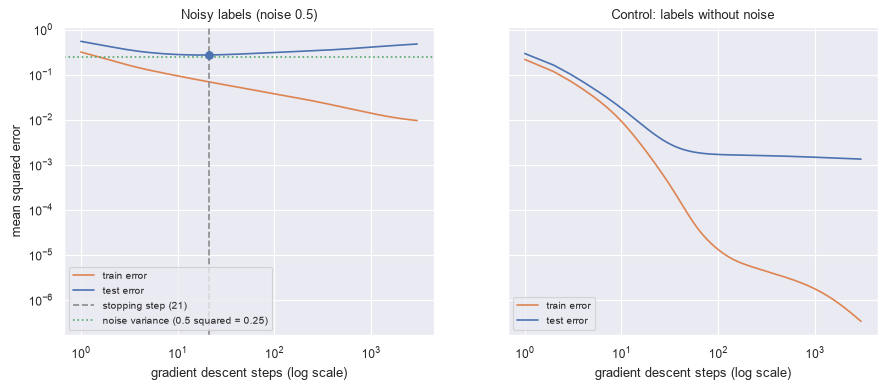

In [8]:
figure, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0), sharey=True)
steps = np.arange(1, STEPS + 1)
for axis, run, title in ((left, noisy, "Noisy labels (noise 0.5)"), (right, clean, "Control: labels without noise")):
    axis.plot(steps, run["train"][1:], color=VERTICAL, label="train error")
    axis.plot(steps, run["test"][1:], color=NEAREST, label="test error")
    if run is noisy:
        axis.axvline(run["stop"], color=BEFORE, linestyle="--", linewidth=1.2, label=f"stopping step ({run['stop']})")
        axis.scatter([run["stop"]], [run["test"][run["stop"]]], color=NEAREST, zorder=4, s=30)
        axis.axhline(0.25, color=BOUND, linestyle=":", linewidth=1.2, label=f"noise variance ({NOISE_LEVEL} squared = {NOISE_LEVEL ** 2:.2f})")
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_xlabel("gradient descent steps (log scale)")
    axis.set_title(title)
    axis.legend(loc="lower left", fontsize=7.5)
left.set_ylabel("mean squared error")
save_figure(figure, "20-stop-on-noise")